In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from arch import arch_model
from scipy.optimize import minimize
import seaborn as sns

In [3]:
files ={
    "CZK": "/Users/eddiechiu/Documents/GitHub/Thesis/data/Czech_koruna.csv",
    "DKK": "/Users/eddiechiu/Documents/GitHub/Thesis/data/Danish_krone.csv",
    "HUF": "/Users/eddiechiu/Documents/GitHub/Thesis/data/Hungarian_forint.csv",
    "PLN": "/Users/eddiechiu/Documents/GitHub/Thesis/data/Polish_zloty.csv",
    "RON": "/Users/eddiechiu/Documents/GitHub/Thesis/data/Romanian_leu.csv",
    "SEK": "/Users/eddiechiu/Documents/GitHub/Thesis/data/Swedish_krona.csv",
    "USD_EUR": "/Users/eddiechiu/Documents/GitHub/Thesis/data/USD_EUR.csv",
}


In [4]:
def load_data(path, currency):
    df = pd.read_csv(path)
    val_col = [c for c in df.columns if c not in ("DATE", "TIME PERIOD")][0]
    out = df[["DATE", val_col]].copy()
    out.columns = ["date", currency]
    out["date"] = pd.to_datetime(out["date"])
    out[currency] = pd.to_numeric(out[currency], errors="coerce")
    return out.set_index("date").sort_index()

rates = pd.concat([load_data(p, c) for c, p in files.items()], axis=1)

In [5]:
rates = rates.loc["2000-01-01":"2024-12-31"] 
rates = rates.dropna()

In [6]:
print(rates.head())
print(rates.shape)

               CZK     DKK     HUF     PLN     RON     SEK  USD_EUR
date                                                               
2000-01-03  36.063  7.4404  254.53  4.1835  1.8273  8.5520   1.0090
2000-01-04  36.270  7.4429  254.52  4.2423  1.8858  8.6215   1.0305
2000-01-05  36.337  7.4444  254.51  4.2627  1.8979  8.6415   1.0368
2000-01-06  36.243  7.4441  254.45  4.2593  1.9000  8.6445   1.0388
2000-01-07  36.027  7.4436  254.63  4.1897  1.8822  8.6450   1.0284
(6399, 7)


In [7]:
returns = np.log(rates / rates.shift(1)).dropna()


In [8]:
model = arch_model(returns["PLN"] * 100, vol="Garch", p=1, q=1, dist="t")
result = model.fit(disp="off")

print(result.summary())

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                          PLN   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -3610.94
Distribution:      Standardized Student's t   AIC:                           7231.89
Method:                  Maximum Likelihood   BIC:                           7265.71
                                              No. Observations:                 6398
Date:                      Thu, Aug 06 2026   Df Residuals:                     6397
Time:                              14:55:07   Df Model:                            1
                                  Mean Model                                  
                 coef    std err          t      P>|t|        95.0% Conf. Int.
-----------------------------------------------------------------------------

In [9]:
results = {}

for currency in returns.columns:
    model = arch_model(returns[currency] * 100, vol="Garch", p=1, q=1, dist="t", rescale=True)
    results[currency] = model.fit(disp="off")
    print(f"\n=== {currency} ===")
    print(results[currency].summary())


=== CZK ===
                        Constant Mean - GARCH Model Results                         
Dep. Variable:                          CZK   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -386.057
Distribution:      Standardized Student's t   AIC:                           782.114
Method:                  Maximum Likelihood   BIC:                           815.933
                                              No. Observations:                 6398
Date:                      Thu, Aug 06 2026   Df Residuals:                     6397
Time:                              14:55:07   Df Model:                            1
                                   Mean Model                                  
                  coef    std err          t      P>|t|        95.0% Conf. Int.
--------------------------------------------------------------

In [10]:
summary_table = pd.DataFrame({
    currency: {
        "alpha": res.params["alpha[1]"],
        "beta": res.params["beta[1]"],
        "alpha+beta": res.params["alpha[1]"] + res.params["beta[1]"],
        "nu": res.params["nu"],
        "converged": res.convergence_flag == 0,
    }
    for currency, res in results.items()
}).T

print(summary_table)

            alpha      beta alpha+beta         nu converged
CZK           0.1      0.88       0.98   4.315329      True
DKK      0.147353  0.852647        1.0   3.925436      True
HUF      0.075874  0.924126        1.0   6.103975      True
PLN      0.094637  0.905312    0.99995   6.518999      True
RON      0.366475  0.065969   0.432443  87.917981      True
SEK      0.056431  0.934689   0.991119   8.729405      True
USD_EUR  0.030212  0.967869    0.99808   7.627595      True


<Axes: title={'center': 'RON log returns'}, xlabel='date'>

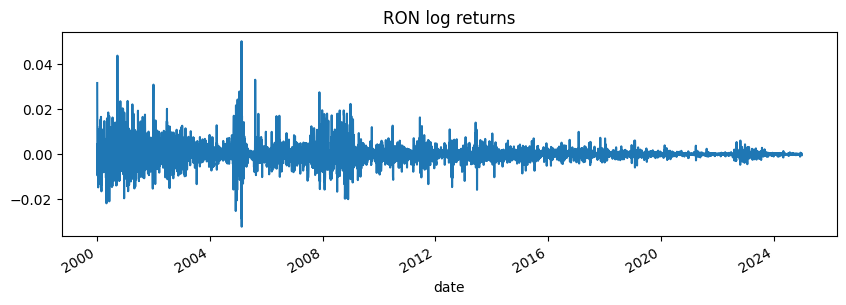

In [11]:
returns["RON"].plot(figsize=(10,3), title="RON log returns")


In [70]:
#new period 

rates_new = rates.loc["2005-01-01":"2025-12-31"] 
rates_new = rates_new.dropna()

returns_new = np.log(rates_new / rates_new.shift(1)).dropna()


In [71]:
# === GARCH(1,1)-t estimation, robust to local optima ===
# A single default-start fit is not reliable here. For CZK and RON the likelihood is
# multimodal, and the optimizer's answer depends on where it starts. Diagnosing that with
# a 21-point start grid showed two distinct failure modes:
#
#   * DEGENERATE optima: omega -> 0 with alpha+beta > 1. These report a *higher* likelihood
#     (CZK 488 vs 180, RON 2467 vs 2119) but are an artifact -- driving the variance
#     intercept to zero lets a few conditional variances collapse, and each near-zero sigma
#     contributes a density spike that inflates the likelihood without describing the data.
#     Chasing the highest likelihood here is chasing the artifact, so these are REJECTED.
#   * Genuine local optima: admissible but sub-optimal (CZK's default start, LL 180 vs 265).
#
# The fix is a multi-start search that keeps the best optimum INSIDE the admissible region.
# Admissibility: omega > 1e-4 (rules out the degenerate corner) and alpha+beta <= 1
# (covariance-stationary, with equality allowed so DKK's genuine IGARCH is retained -- for a
# hard peg, permanent variance shocks are the honest description, not a numerical failure).
#
# Effect: HUF, PLN, RON, SEK, USD_EUR and DKK are bit-identical to the single-start fit
# (corr(std_resid) = 1.00000). Only CZK moves, and only slightly (corr = 0.995).
import itertools

OMEGA_MIN = 1e-4          # below this, the omega -> 0 pathology
PERS_MAX  = 1.0 + 1e-9    # allow alpha+beta == 1 exactly (IGARCH), reject > 1

START_GRID = [(a, b, nu)
              for a, b, nu in itertools.product((0.03, 0.06, 0.10, 0.15),
                                                (0.80, 0.86, 0.92, 0.96),
                                                (5.0, 8.0))
              if a + b < 0.999]

def fit_garch_robust(y, label=""):
    """GARCH(1,1)-t via multi-start; returns the best ADMISSIBLE optimum."""
    mdl = arch_model(y, vol="Garch", p=1, q=1, dist="t", rescale=True)
    cands = [("default", mdl.fit(disp="off", options={"maxiter": 30000}))]
    for a, b, nu in START_GRID:
        try:
            cands.append((f"a={a},b={b},nu={nu}", mdl.fit(
                disp="off",
                starting_values=np.array([y.mean(), y.var() * (1 - a - b), a, b, nu]),
                options={"maxiter": 30000})))
        except Exception:
            continue                      # a failed start is information, not an error

    ok = [(n, r) for n, r in cands
          if r.params["omega"] > OMEGA_MIN
          and r.params["alpha[1]"] + r.params["beta[1]"] < PERS_MAX
          and np.isfinite(r.loglikelihood)]
    if not ok:
        raise RuntimeError(f"{label}: no admissible optimum over {len(cands)} starts")

    name, best = max(ok, key=lambda t: t[1].loglikelihood)
    p = best.params
    print(f"{label:8s} admissible {len(ok):2d}/{len(cands):2d} starts | best='{name}' "
          f"LL={best.loglikelihood:9.1f} alpha={p['alpha[1]']:.4f} beta={p['beta[1]']:.4f} "
          f"a+b={p['alpha[1]'] + p['beta[1]']:.5f} omega={p['omega']:.5f} "
          f"nu={p['nu']:5.2f} converged={best.convergence_flag == 0}")
    return best

results_new = {c: fit_garch_robust(returns_new[c] * 100, c) for c in returns_new.columns}

print("\n=== retained parameters ===")
print(pd.DataFrame({c: {"alpha": r.params["alpha[1]"], "beta": r.params["beta[1]"],
                        "alpha+beta": r.params["alpha[1]"] + r.params["beta[1]"],
                        "omega": r.params["omega"], "nu": r.params["nu"],
                        "logL": r.loglikelihood,
                        "converged": r.convergence_flag == 0}
                    for c, r in results_new.items()}).T.round(5).to_string())
print("\nDKK sits at alpha+beta = 1 exactly: genuine IGARCH for a hard peg, not a failure.")

/var/folders/s_/_nfn0dv128bfblp2pcw4b06w0000gn/T/ipykernel_22055/1894121442.py:34: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  cands = [("default", mdl.fit(disp="off", options={"maxiter": 30000}))]
/var/folders/s_/_nfn0dv128bfblp2pcw4b06w0000gn/T/ipykernel_22055/1894121442.py:37: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  cands.append((f"a={a},b={b},nu={nu}", mdl.fit(
/var/folders/s_/_nfn0dv128bfblp2pcw4b06w0000gn/T/ipykernel_22055/1894121442.py:37: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  cands.append((f"a={a},b={b},nu={nu}", mdl.fit(


CZK      admissible 12/21 starts | best='a=0.03,b=0.8,nu=8.0' LL=    212.0 alpha=0.1544 beta=0.8452 a+b=0.99963 omega=0.00029 nu= 5.48 converged=True
DKK      admissible 21/21 starts | best='a=0.03,b=0.92,nu=8.0' LL=  -8054.0 alpha=0.1544 beta=0.8456 a+b=1.00000 omega=0.04201 nu= 3.86 converged=True
HUF      admissible 21/21 starts | best='a=0.15,b=0.8,nu=5.0' LL=  -3283.9 alpha=0.0695 beta=0.9280 a+b=0.99752 omega=0.00140 nu= 7.77 converged=True
PLN      admissible 21/21 starts | best='a=0.03,b=0.86,nu=5.0' LL=  -2456.9 alpha=0.0928 beta=0.9054 a+b=0.99819 omega=0.00147 nu= 6.51 converged=True


/var/folders/s_/_nfn0dv128bfblp2pcw4b06w0000gn/T/ipykernel_22055/1894121442.py:37: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  cands.append((f"a={a},b={b},nu={nu}", mdl.fit(
/var/folders/s_/_nfn0dv128bfblp2pcw4b06w0000gn/T/ipykernel_22055/1894121442.py:37: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  cands.append((f"a={a},b={b},nu={nu}", mdl.fit(


RON      admissible 18/21 starts | best='default' LL=   1595.2 alpha=0.1981 beta=0.7436 a+b=0.94171 omega=0.00200 nu= 5.27 converged=True
SEK      admissible 21/21 starts | best='a=0.1,b=0.86,nu=8.0' LL=  -2205.1 alpha=0.0505 beta=0.9416 a+b=0.99209 omega=0.00143 nu= 8.01 converged=True
USD_EUR  admissible 21/21 starts | best='a=0.06,b=0.86,nu=5.0' LL=  -3772.3 alpha=0.0309 beta=0.9666 a+b=0.99744 omega=0.00090 nu= 6.92 converged=True

=== retained parameters ===
            alpha      beta alpha+beta     omega        nu         logL converged
CZK       0.15438  0.845248   0.999627  0.000294  5.477999   212.016378      True
DKK        0.1544    0.8456        1.0  0.042008   3.86268 -8053.984861      True
HUF       0.06955  0.927968   0.997517  0.001402  7.769632 -3283.933373      True
PLN      0.092802  0.905386   0.998188  0.001468  6.508236 -2456.876079      True
RON      0.198104  0.743607   0.941712  0.002001  5.266542  1595.223796      True
SEK      0.050471  0.941621   0.992092  

In [72]:
summary_table = pd.DataFrame({
    currency: {
        "alpha": res.params["alpha[1]"],
        "beta": res.params["beta[1]"],
        "alpha+beta": res.params["alpha[1]"] + res.params["beta[1]"],
        "nu": res.params["nu"],
        "converged": res.convergence_flag == 0,
    }
    for currency, res in results_new.items()
}).T

print(summary_table)

            alpha      beta alpha+beta        nu converged
CZK       0.15438  0.845248   0.999627  5.477999      True
DKK        0.1544    0.8456        1.0   3.86268      True
HUF       0.06955  0.927968   0.997517  7.769632      True
PLN      0.092802  0.905386   0.998188  6.508236      True
RON      0.198104  0.743607   0.941712  5.266542      True
SEK      0.050471  0.941621   0.992092  8.005655      True
USD_EUR  0.030872   0.96657   0.997443  6.924102      True


<Axes: title={'center': 'PLN log returns'}, xlabel='date'>

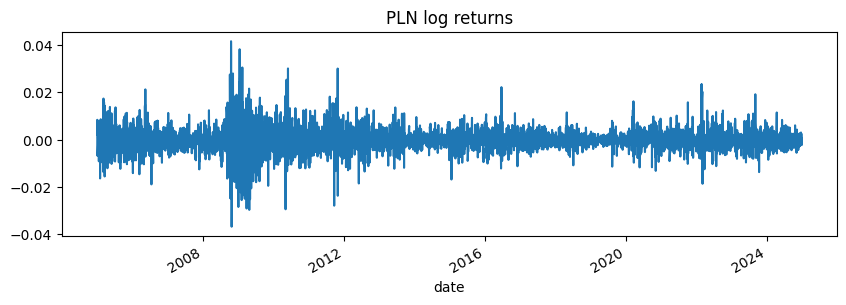

In [73]:
returns_new["PLN"].plot(figsize=(10,3), title="PLN log returns")



In [74]:
#maxiter adjustment dont work
#fix the CZK convergence issue by adjusting the optimization method and maxiter parameter


In [75]:
#standardized residuals
std_resid = {}

for currency, result in results_new.items():
    std_resid[currency] = result.std_resid

std_resid_df = pd.DataFrame(std_resid)
std_resid_df = std_resid_df.dropna()

print(std_resid_df.shape)
print(std_resid_df.head())
print(std_resid_df.isna().sum())

(5120, 7)
                 CZK       DKK       HUF       PLN       RON       SEK  \
date                                                                     
2005-01-04  0.057122 -1.417127 -0.257369  0.403223 -0.684146  3.060602   
2005-01-05  0.734860  2.934256  1.029462  1.632635 -0.721412 -0.065613   
2005-01-06  0.112082  0.173261  2.266968 -0.033662  0.309228 -0.158449   
2005-01-07 -1.755535 -0.051501  0.729241 -1.255276  0.736950 -0.191203   
2005-01-10 -0.654987  0.203101 -0.891686 -0.644558 -1.164021  0.552030   

             USD_EUR  
date                  
2005-01-04 -1.770152  
2005-01-05 -1.720650  
2005-01-06 -0.488584  
2005-01-07  0.206528  
2005-01-10 -1.193755  
CZK        0
DKK        0
HUF        0
PLN        0
RON        0
SEK        0
USD_EUR    0
dtype: int64


In [76]:
print(std_resid_df.index.min(), "→", std_resid_df.index.max())
print("PLN original result count:", len(results["PLN"].std_resid))

2005-01-04 00:00:00 → 2024-12-31 00:00:00
PLN original result count: 6398


In [77]:
# epsilon_t = standardized residuals from each currency's GARCH fit
epsilon = std_resid_df.values   # T x n matrix, rows = time, columns = currencies
T, n = epsilon.shape

# S = unconditional correlation matrix of epsilon_t (paper's S / Q_bar)
S = np.corrcoef(epsilon.T)

def dcc_loglik(params, epsilon, S):
    alpha, beta = params
    if alpha < 0 or beta < 0 or alpha + beta >= 1:
        return 1e10

    T, n = epsilon.shape
    Q_t = S.copy()
    loglik = 0

    for t in range(1, T):
        eps_prev = epsilon[t-1].reshape(-1, 1)

        # Eq. 22: Q_t = (1-alpha-beta)S + alpha * eps_{t-1} eps_{t-1}' + beta * Q_{t-1}
        Q_t = (1 - alpha - beta) * S + alpha * (eps_prev @ eps_prev.T) + beta * Q_t

        # Eq. 23-24: R_t = (I ⊙ Q_t^{1/2})^{-1} Q_t (I ⊙ Q_t^{1/2})^{-1}
        q_diag_sqrt = np.sqrt(np.diag(Q_t))
        R_t = Q_t / np.outer(q_diag_sqrt, q_diag_sqrt)

        eps_t = epsilon[t]
        try:
            R_t_inv = np.linalg.inv(R_t)
            sign, logdet_R_t = np.linalg.slogdet(R_t)
            if sign <= 0:
                return 1e10
            # QML log-likelihood contribution (Eq. 25, Gaussian form)
            loglik += -0.5 * (logdet_R_t + eps_t @ R_t_inv @ eps_t)
        except np.linalg.LinAlgError:
            return 1e10

    return -loglik  # scipy minimizes, so return negative log-likelihood

# Estimate alpha, beta via QML
result = minimize(
    dcc_loglik, x0=[0.05, 0.90],
    args=(epsilon, S), method="Nelder-Mead"
)
alpha_hat, beta_hat = result.x
print("Converged:", result.success)
print("alpha:", alpha_hat, "beta:", beta_hat, "alpha+beta:", alpha_hat + beta_hat)

Converged: True
alpha: 0.007693098486573933 beta: 0.9852943318846938 alpha+beta: 0.9929874303712678


In [78]:
#MLE reestimation of DCC parameters a,b
def compute_R_series(epsilon, S, alpha, beta):
    T, n = epsilon.shape
    Q_t = S.copy()
    R_series = np.zeros((T, n, n))

    for t in range(T):
        q_diag_sqrt = np.sqrt(np.diag(Q_t))
        R_t = Q_t / np.outer(q_diag_sqrt, q_diag_sqrt)
        R_series[t] = R_t

        if t < T - 1:
            eps_t = epsilon[t].reshape(-1, 1)
            Q_t = (1 - alpha - beta) * S + alpha * (eps_t @ eps_t.T) + beta * Q_t

    return R_series

R_series = compute_R_series(epsilon, S, alpha_hat, beta_hat)
print(R_series.shape)

(5120, 7, 7)


In [79]:
currencies = std_resid_df.columns.tolist()
n = len(currencies)

pairwise_corr = {}
for i in range(n):
    for j in range(i+1, n):
        pair_name = f"{currencies[i]}_{currencies[j]}"
        pairwise_corr[pair_name] = R_series[:, i, j]

corr_df = pd.DataFrame(pairwise_corr, index=std_resid_df.index)
print(corr_df.head())
print(corr_df.describe())

             CZK_DKK   CZK_HUF   CZK_PLN   CZK_RON   CZK_SEK  CZK_USD_EUR  \
date                                                                        
2005-01-04 -0.006942  0.321318  0.350826  0.136739  0.120119    -0.135498   
2005-01-05 -0.007512  0.321117  0.350779  0.136187  0.117289    -0.134655   
2005-01-06  0.008900  0.324997  0.355709  0.131513  0.116696    -0.142518   
2005-01-07  0.008936  0.320577  0.355626  0.131766  0.116568    -0.142754   
2005-01-10  0.009400  0.306359  0.366157  0.119895  0.117719    -0.143743   

             DKK_HUF   DKK_PLN   DKK_RON   DKK_SEK  ...   HUF_PLN   HUF_RON  \
date                                                ...                       
2005-01-04 -0.025897 -0.012646  0.018856  0.028369  ...  0.560612  0.270741   
2005-01-05 -0.022886 -0.016934  0.026122 -0.005037  ...  0.559311  0.271544   
2005-01-06  0.000487  0.019374  0.009364 -0.006053  ...  0.564248  0.264121   
2005-01-07  0.003202  0.019110  0.009829 -0.006023  ...  0.552655

In [80]:
print(R_series.shape)
print(corr_df.describe())

(5120, 7, 7)


           CZK_DKK      CZK_HUF      CZK_PLN      CZK_RON      CZK_SEK  \
count  5120.000000  5120.000000  5120.000000  5120.000000  5120.000000   
mean     -0.006832     0.325740     0.357280     0.138572     0.124340   
std       0.049629     0.100345     0.099881     0.068552     0.081009   
min      -0.136151    -0.010691     0.067856    -0.086695    -0.138350   
25%      -0.041938     0.252441     0.295265     0.093318     0.076215   
50%      -0.002667     0.332715     0.358527     0.133379     0.119628   
75%       0.026755     0.400864     0.438356     0.180275     0.176810   
max       0.159283     0.551161     0.557729     0.325647     0.343710   

       CZK_USD_EUR      DKK_HUF      DKK_PLN      DKK_RON      DKK_SEK  ...  \
count  5120.000000  5120.000000  5120.000000  5120.000000  5120.000000  ...   
mean     -0.136704    -0.026817    -0.012329     0.018705     0.028387  ...   
std       0.082659     0.040834     0.047365     0.050262     0.049645  ...   
min      -0.32158

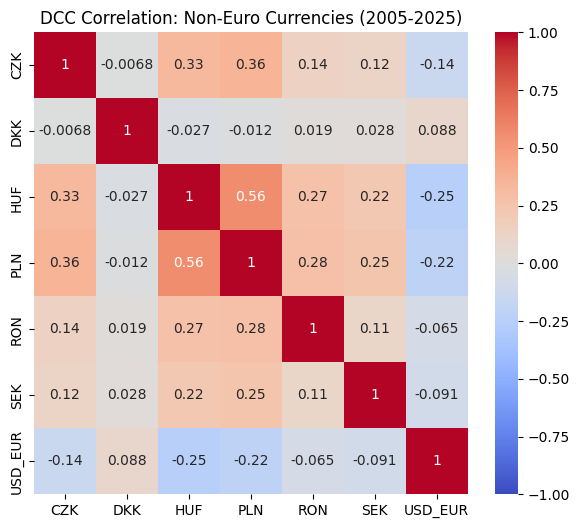

In [81]:
mean_corr = {}
for i in range(len(currencies)):
    for j in range(len(currencies)):
        if i == j:
            mean_corr[(currencies[i], currencies[j])] = 1.0
        else:
            key = f"{currencies[min(i,j)]}_{currencies[max(i,j)]}"
            if key in corr_df.columns:
                mean_corr[(currencies[i], currencies[j])] = corr_df[key].mean()


corr_matrix = pd.DataFrame(index=currencies, columns=currencies, dtype=float)
for (a, b), v in mean_corr.items():
    corr_matrix.loc[a, b] = v

plt.figure(figsize=(7,6))
sns.heatmap(corr_matrix.astype(float), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("DCC Correlation: Non-Euro Currencies (2005-2025)")
plt.show()

(5120, 21)


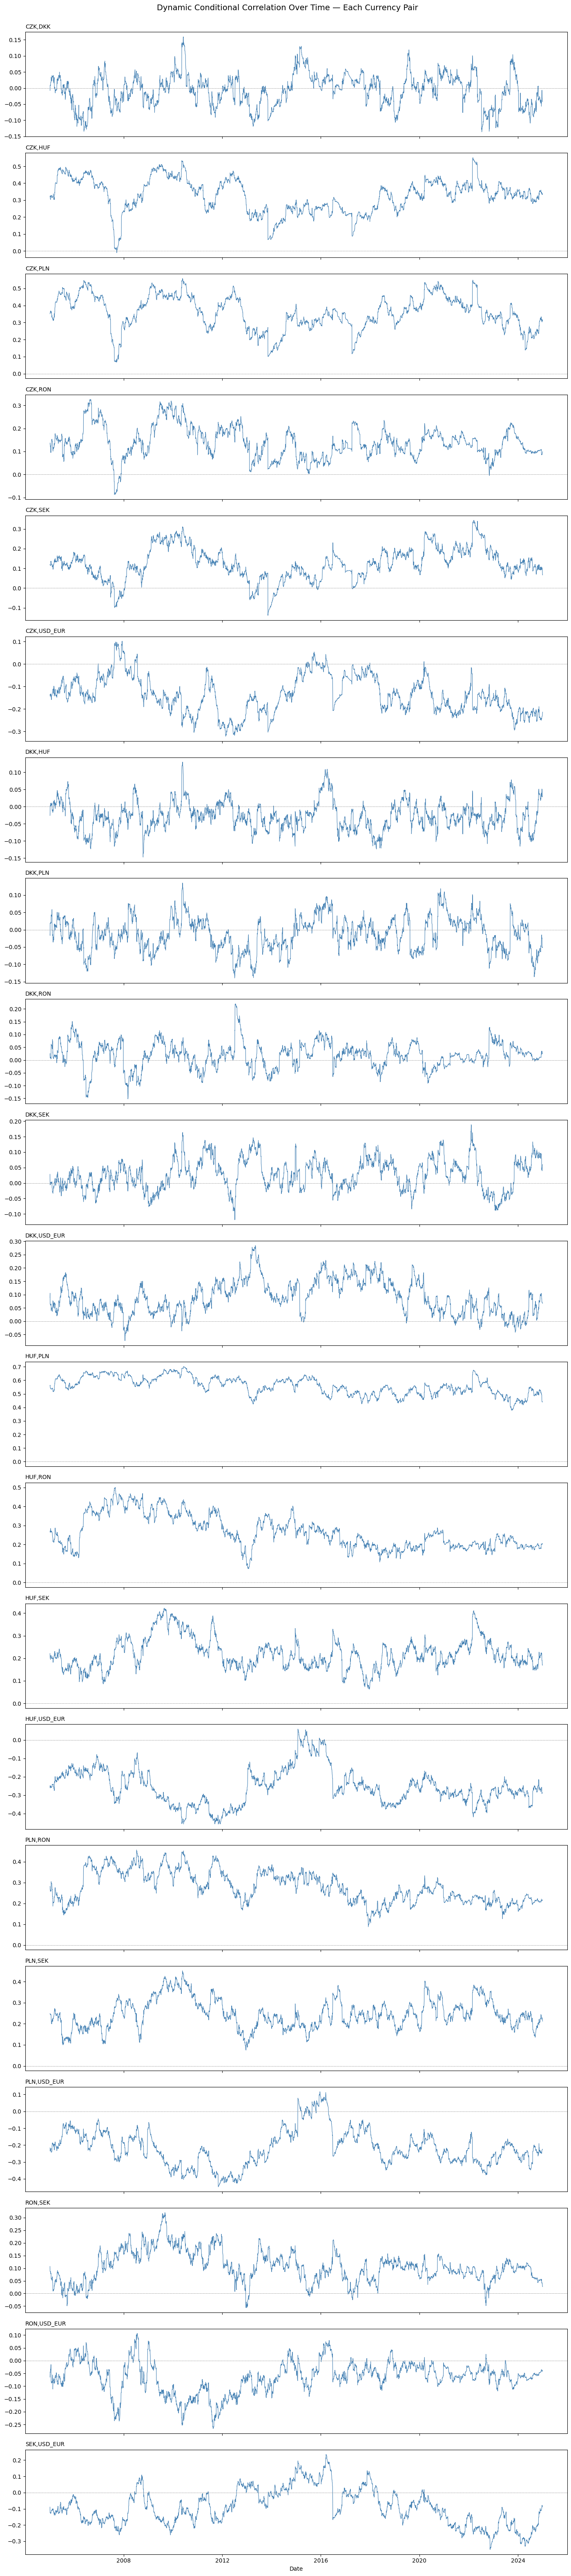

In [82]:
pairwise_series = {}

for i in range(len(currencies)):
    for j in range(i+1, len(currencies)):  # unique pairs only
        key = f"{currencies[i]},{currencies[j]}"
        pairwise_series[key] = R_series[:, i, j]

pairwise_df = pd.DataFrame(pairwise_series, index=std_resid_df.index)
print(pairwise_df.shape)  # (T, 15)

n_pairs = len(pairwise_df.columns)

fig, axes = plt.subplots(
    nrows=n_pairs, ncols=1,
    figsize=(14, 3 * n_pairs),   # scales height with number of pairs
    sharex=True
)

for ax, col in zip(axes, pairwise_df.columns):
    ax.plot(pairwise_df.index, pairwise_df[col], linewidth=0.8, color="steelblue")
    ax.set_title(col, loc="left", fontsize=10)
    ax.axhline(0, color="gray", linewidth=0.5, linestyle="--")
    #ax.set_ylim(-1, 1)

axes[-1].set_xlabel("Date")
fig.suptitle("Dynamic Conditional Correlation Over Time — Each Currency Pair", fontsize=14, y=1.0)
plt.tight_layout()
plt.show()

In [83]:
pairwise_annual = pairwise_df.resample("Y").mean()
print(pairwise_annual.shape)   # should be roughly (20, 15) — 20 years, 15 pairs
print(pairwise_annual.head())

rho_annual = pd.DataFrame(index=pairwise_annual.index)

for ccy in currencies:
    others = [c for c in currencies if c != ccy]
    pair_cols = []
    for o in others:
        key1 = f"{ccy},{o}"
        key2 = f"{o},{ccy}"
        if key1 in pairwise_annual.columns:
            pair_cols.append(key1)
        elif key2 in pairwise_annual.columns:
            pair_cols.append(key2)
    rho_annual[ccy] = pairwise_annual[pair_cols].mean(axis=1)

print(rho_annual)

(20, 21)
             CZK,DKK   CZK,HUF   CZK,PLN   CZK,RON   CZK,SEK  CZK,USD_EUR  \
date                                                                        
2005-12-31  0.001539  0.425411  0.421956  0.130176  0.129409    -0.115056   
2006-12-31 -0.065292  0.426749  0.481943  0.216048  0.110373    -0.116161   
2007-12-31 -0.017012  0.224794  0.274449  0.096295  0.001603    -0.007854   
2008-12-31  0.000370  0.302444  0.348700  0.115580  0.088468    -0.059855   
2009-12-31 -0.010335  0.467533  0.473696  0.248881  0.237435    -0.152344   

             DKK,HUF   DKK,PLN   DKK,RON   DKK,SEK  ...   HUF,PLN   HUF,RON  \
date                                                ...                       
2005-12-31  0.008233  0.010150  0.048724  0.004183  ...  0.572437  0.210099   
2006-12-31 -0.061885 -0.046576 -0.005649 -0.007902  ...  0.623800  0.313304   
2007-12-31 -0.046739 -0.021503  0.047903  0.028510  ...  0.646424  0.420076   
2008-12-31 -0.024599 -0.004019 -0.049024  0.011876  ... 

/var/folders/s_/_nfn0dv128bfblp2pcw4b06w0000gn/T/ipykernel_22055/2401099408.py:1: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  pairwise_annual = pairwise_df.resample("Y").mean()


In [84]:
rho_long = rho_annual.reset_index().melt(id_vars="date", var_name="currency", value_name="rho")
rho_long["year"] = rho_long["date"].dt.year
rho_long = rho_long.drop(columns="date")

print(rho_long.head())
print(rho_long.shape)  # roughly 20 years x 6 currencies = ~120 row

  currency       rho  year
0      CZK  0.165573  2005
1      CZK  0.175610  2006
2      CZK  0.095379  2007
3      CZK  0.132618  2008
4      CZK  0.210811  2009
(140, 3)


In [85]:
#https://ec.europa.eu/eurostat/databrowser/view/nama_10_gdp__custom_22265205/default/table
df = pd.read_csv("/Users/eddiechiu/Documents/GitHub/Thesis/data/nama_10_gdp__custom_22265205_linear_2_0.csv")
print(df.head())
print(df.columns.tolist())

  STRUCTURE            STRUCTURE_ID  \
0  dataflow  ESTAT:NAMA_10_GDP(1.0)   
1  dataflow  ESTAT:NAMA_10_GDP(1.0)   
2  dataflow  ESTAT:NAMA_10_GDP(1.0)   
3  dataflow  ESTAT:NAMA_10_GDP(1.0)   
4  dataflow  ESTAT:NAMA_10_GDP(1.0)   

                                      STRUCTURE_NAME freq Time frequency  \
0  Gross domestic product (GDP) and main componen...    A         Annual   
1  Gross domestic product (GDP) and main componen...    A         Annual   
2  Gross domestic product (GDP) and main componen...    A         Annual   
3  Gross domestic product (GDP) and main componen...    A         Annual   
4  Gross domestic product (GDP) and main componen...    A         Annual   

      unit               Unit of measure na_item  \
0  CP_MEUR  Current prices, million euro    B1GQ   
1  CP_MEUR  Current prices, million euro    B1GQ   
2  CP_MEUR  Current prices, million euro    B1GQ   
3  CP_MEUR  Current prices, million euro    B1GQ   
4  CP_MEUR  Current prices, million euro    B1GQ

In [86]:
gdp_raw = pd.read_csv("/Users/eddiechiu/Documents/GitHub/Thesis/data/nama_10_gdp__custom_22265205_linear_2_0.csv")

gdp = gdp_raw[["geo", "TIME_PERIOD", "OBS_VALUE"]].copy()
gdp.columns = ["country", "year", "gdp_meur"]

# filter to your six countries and your window
your_countries = ["PL", "CZ", "HU", "RO", "SE", "DK"]
gdp = gdp[gdp["country"].isin(your_countries)]
gdp = gdp[(gdp["year"] >= 2005) & (gdp["year"] <= 2025)]

# pivot so each country is a column, year is the index — easy to inspect
gdp_wide = gdp.pivot(index="year", columns="country", values="gdp_meur")
print(gdp_wide)

country        CZ        DK        HU        PL        RO        SE
year                                                               
2005     110418.8  213381.8   90999.5  246903.6   79223.9  315348.4
2006     124559.0  225930.8   92038.0  275514.0   97215.6  336866.7
2007     138897.5  233960.3  102368.2  314356.3  127632.0  358064.8
2008     161852.2  242720.1  108278.8  367420.9  146589.7  352761.6
2009     149253.1  232270.0   94416.6  317876.9  125219.8  313033.6
2010     159506.1  243429.9   99562.8  360890.7  128305.3  372381.5
2011     166545.5  248105.0  101986.9  379540.6  138528.2  410287.8
2012     163759.4  254300.7   99979.9  387660.3  139307.7  427901.2
2013     160470.0  259530.9  102210.9  390177.0  142936.0  439805.4
2014     158991.5  265635.7  106335.3  408714.7  150528.8  435639.5
2015     170527.3  272193.0  112854.0  432485.8  160289.0  452337.2
2016     179145.9  282265.1  116593.5  427658.6  167497.1  463918.8
2017     196738.7  294355.0  127222.5  469071.2 

In [87]:
#https://ec.europa.eu/eurostat/databrowser/view/ds-045409__custom_22289115/default/table
trade_raw = pd.read_csv("/Users/eddiechiu/Documents/GitHub/Thesis/data/ds-045409__custom_22289115_linear_2_0 (1).csv")

print("Shape:", trade_raw.shape)
print("Columns:", trade_raw.columns.tolist())
print(trade_raw.head())

# lowercase 'flow' is the numeric code, uppercase 'FLOW' the text label
print(trade_raw[["flow", "FLOW"]].head(10))
print(trade_raw["flow"].dtype, trade_raw["FLOW"].dtype)
print(trade_raw["flow"].unique())
print(trade_raw["FLOW"].unique())


Shape: (5040, 19)
Columns: ['STRUCTURE', 'STRUCTURE_ID', 'STRUCTURE_NAME', 'freq', 'Frequency', 'reporter', 'REPORTER', 'partner', 'PARTNER', 'product', 'PRODUCT', 'flow', 'FLOW', 'indicators', 'INDICATORS', 'TIME_PERIOD', 'TIME_PERIOD.1', 'OBS_VALUE', 'Observation Value']
  STRUCTURE          STRUCTURE_ID                          STRUCTURE_NAME  \
0  dataflow  ESTAT:DS-045409(1.0)  EU trade since 1988 by HS2-4-6 and CN8   
1  dataflow  ESTAT:DS-045409(1.0)  EU trade since 1988 by HS2-4-6 and CN8   
2  dataflow  ESTAT:DS-045409(1.0)  EU trade since 1988 by HS2-4-6 and CN8   
3  dataflow  ESTAT:DS-045409(1.0)  EU trade since 1988 by HS2-4-6 and CN8   
4  dataflow  ESTAT:DS-045409(1.0)  EU trade since 1988 by HS2-4-6 and CN8   

  freq Frequency reporter REPORTER partner  PARTNER product PRODUCT  flow  \
0    A    Annual       CZ  Czechia      AT  Austria   TOTAL   Total     1   
1    A    Annual       CZ  Czechia      AT  Austria   TOTAL   Total     1   
2    A    Annual       CZ  Czech

In [88]:


# explicitly select uppercase FLOW (the text labels), not lowercase flow (numeric codes)
trade = trade_raw[["reporter", "partner", "TIME_PERIOD", "FLOW", "OBS_VALUE"]].copy()
trade.columns = ["country", "partner", "year", "flow_label", "value"]

print(trade["flow_label"].unique())   # should show ['IMPORT' 'EXPORT']

# filter to your window
trade = trade[(trade["year"] >= 2005) & (trade["year"] <= 2025)]

# split
exports = trade[trade["flow_label"] == "EXPORT"]
imports = trade[trade["flow_label"] == "IMPORT"]

print("exports shape:", exports.shape)
print("imports shape:", imports.shape)

# sum across all 20 Eurozone partners, per reporting country per year
exports_summed = exports.groupby(["country", "year"])["value"].sum().reset_index()
exports_summed.columns = ["country", "year", "exports_to_EA"]

imports_summed = imports.groupby(["country", "year"])["value"].sum().reset_index()
imports_summed.columns = ["country", "year", "imports_from_EA"]

trade_final = exports_summed.merge(imports_summed, on=["country", "year"])
trade_final["trade_volume_EA"] = trade_final["exports_to_EA"] + trade_final["imports_from_EA"]
trade_final["trade_balance_EA"] = trade_final["exports_to_EA"] - trade_final["imports_from_EA"]

trade_final["exports_to_EA_meur"] = trade_final["exports_to_EA"] / 1_000_000
trade_final["imports_from_EA_meur"] = trade_final["imports_from_EA"] / 1_000_000
trade_final["trade_volume_EA_meur"] = trade_final["trade_volume_EA"] / 1_000_000

print(trade_final.head(20))
print(trade_final.shape)
print(trade_final["country"].unique())

['IMPORT' 'EXPORT']
exports shape: (2520, 5)
imports shape: (2520, 5)
   country  year  exports_to_EA  imports_from_EA  trade_volume_EA  \
0       CZ  2005    43629918412      42087254365      85717172777   
1       CZ  2006    51758021403      49435642199     101193663602   
2       CZ  2007    60039793848      56654792423     116694586271   
3       CZ  2008    66551443953      60225865708     126777309661   
4       CZ  2009    55047270237      47726739456     102774009693   
5       CZ  2010    67200197153      57629048339     124829245492   
6       CZ  2011    77688147813      65458144676     143146292489   
7       CZ  2012    78493163072      65830650085     144323813157   
8       CZ  2013    77696195052      65489636239     143185831291   
9       CZ  2014    84245520836      70202634145     154448154981   
10      CZ  2015    92223874059      76002317790     168226191849   
11      CZ  2016    96172620901      77823896064     173996516965   
12      CZ  2017   105638930680  

In [89]:
czk_trade = trade_final[trade_final["country"] == "CZ"]
czk_gdp = gdp_wide["CZ"].reset_index()
czk_gdp.columns = ["year", "gdp_meur"]

check = czk_trade.merge(czk_gdp, on="year")
check["trade_pct_gdp"] = check["trade_volume_EA_meur"] / check["gdp_meur"] * 100
print(check[["year", "trade_volume_EA_meur", "gdp_meur", "trade_pct_gdp"]])

gdp_long = gdp_wide.reset_index().melt(id_vars="year", var_name="country", value_name="gdp_meur")

trade_gdp_check = trade_final.merge(gdp_long, on=["country", "year"])
trade_gdp_check["trade_pct_gdp"] = trade_gdp_check["trade_volume_EA_meur"] / trade_gdp_check["gdp_meur"] * 100

print(trade_gdp_check.groupby("country")["trade_pct_gdp"].describe())

    year  trade_volume_EA_meur  gdp_meur  trade_pct_gdp
0   2005          85717.172777  110418.8      77.629147
1   2006         101193.663602  124559.0      81.241551
2   2007         116694.586271  138897.5      84.014893
3   2008         126777.309661  161852.2      78.329062
4   2009         102774.009693  149253.1      68.858878
5   2010         124829.245492  159506.1      78.259857
6   2011         143146.292489  166545.5      85.950261
7   2012         144323.813157  163759.4      88.131621
8   2013         143185.831291  160470.0      89.229034
9   2014         154448.154981  158991.5      97.142398
10  2015         168226.191849  170527.3      98.650593
11  2016         173996.516965  179145.9      97.125593
12  2017         191309.469661  196738.7      97.240385
13  2018         204085.653281  213505.4      95.588052
14  2019         209182.273255  229406.7      91.184030
15  2020         195795.169493  220310.6      88.872333
16  2021         228889.396735  246012.3      93

## Stage 2 — Exchange-rate volatility and real GDP growth

Stage 1 (univariate GARCH(1,1)-t per currency) supplies the main regressor: the annual mean conditional volatility of each currency against the euro, divided by `res.scale` to undo `arch`'s per-series rescaling.

**Specification.** `real GDP growth ~ volatility + euro-area trade intensity + (volatility x trade intensity) + controls`, estimated on a balanced panel of 6 countries x 2005-2024 (n = 120). Three nested specifications — pooled OLS, country fixed effects, two-way (country + year) fixed effects — with Driscoll-Kraay standard errors as the headline, since these economies share European and global shocks and their residuals are therefore cross-sectionally dependent.

**Dependent variable is real growth (`CLV_PCH_PRE`), never `CP_MEUR`.** Euro-denominated GDP is mechanically tied to the exchange rate: using it yields corr(growth, depreciation) = -0.74, against -0.001 for the real series, and the pegged krone shows only -0.06 — the peg is what proves the mechanism is an artifact of the units rather than economics.

In [99]:
# === Stage 2 panel: annual mean conditional volatility -> real GDP growth ===
# Dependent variable is REAL growth (CLV_PCH_PRE). CP_MEUR is deliberately avoided for the
# dependent variable: euro-denominated GDP is mechanically tied to the exchange rate, and
# using it produces corr(growth, depreciation) = -0.74 -- a relationship you built yourself.
# CP_MEUR is still safe inside RATIOS (GFCF/GDP), where the conversion cancels.
import glob, os
import statsmodels.api as sm

D = "/Users/eddiechiu/Documents/GitHub/Thesis/data/"
GEO = {"CZK": "CZ", "DKK": "DK", "HUF": "HU", "PLN": "PL", "RON": "RO", "SEK": "SE"}

# --- main regressor: annual mean conditional volatility, CORRECTED for arch's rescaling ---
# arch(rescale=True) scaled DKK by 100x and the rest by 1x; raw conditional_volatility is
# therefore NOT comparable across currencies. Dividing by res.scale restores comparability.
print("arch rescale factors:", {c: results_new[c].scale for c in GEO})
cond_vol = pd.DataFrame(
    {c: np.asarray(results_new[c].conditional_volatility) / results_new[c].scale for c in GEO},
    index=returns_new.index)
vol = cond_vol.resample("YE").mean().stack().rename("vol").reset_index()
vol.columns = ["date", "currency", "vol"]
vol["year"] = vol["date"].dt.year
vol["country"] = vol["currency"].map(GEO)
vol = vol[["country", "currency", "year", "vol"]]

# --- dependent variable + GDP levels (levels used only as ratio denominators) ---
_G = pd.read_csv(D + "nama_10_gdp__custom_22321200_linear_2_0.csv")
gdp_growth = _G[(_G.unit == "CLV_PCH_PRE") & (_G.na_item == "B1GQ")][["geo", "TIME_PERIOD", "OBS_VALUE"]]
gdp_growth.columns = ["country", "year", "gdp_growth"]
gdp_lvl = _G[(_G.unit == "CP_MEUR") & (_G.na_item == "B1GQ")][["geo", "TIME_PERIOD", "OBS_VALUE"]]
gdp_lvl.columns = ["country", "year", "gdp_meur"]

# --- euro-area trade intensity: (exports + imports with EA20) / GDP ---
_t = pd.read_csv(D + "ds-045409__custom_22289115_linear_2_0 (1).csv")[
    ["reporter", "TIME_PERIOD", "FLOW", "OBS_VALUE"]]
_t.columns = ["country", "year", "flow", "val"]        # uppercase FLOW = labels, lowercase = codes
trade = (_t.pivot_table(index=["country", "year"], columns="flow", values="val", aggfunc="sum")
           .assign(vol_eur=lambda d: (d["EXPORT"] + d["IMPORT"]) / 1e6)["vol_eur"].reset_index()
           .merge(gdp_lvl, on=["country", "year"]))
trade["trade_int"] = trade["vol_eur"] / trade["gdp_meur"] * 100

# --- controls: loaded if present, silently omitted (with a printed warning) if not ---
def _load_ctrl(pattern, na_item, unit, name, coicop=None):
    for f in sorted(glob.glob(D + pattern)):
        try: d = pd.read_csv(f)
        except Exception: continue
        if "unit" not in d or unit not in set(d["unit"].astype(str)): continue
        if na_item and ("na_item" not in d or na_item not in set(d["na_item"].astype(str))): continue
        if coicop and ("coicop" not in d or coicop not in set(d["coicop"].astype(str))): continue
        m = d["unit"].astype(str) == unit
        if na_item: m &= d["na_item"].astype(str) == na_item
        if coicop:  m &= d["coicop"].astype(str) == coicop
        o = d[m][["geo", "TIME_PERIOD", "OBS_VALUE"]].copy()
        o.columns = ["country", "year", name]
        print(f"  [{name}] loaded from {os.path.basename(f)} ({len(o)} rows)")
        return o
    print(f"  [{name}] NOT FOUND -> omitted; download it and re-run this cell")
    return None

print("\ncontrols:")
_gf = _load_ctrl("nama_10_gdp*.csv", "P51G", "CP_MEUR", "gfcf_meur")
gfcf = None
if _gf is not None:
    gfcf = _gf.merge(gdp_lvl, on=["country", "year"])
    gfcf["gfcf_pct_gdp"] = gfcf["gfcf_meur"] / gfcf["gdp_meur"] * 100   # ratio -> FX cancels
    gfcf = gfcf[["country", "year", "gfcf_pct_gdp"]]
hicp = _load_ctrl("prc_hicp*.csv", None, "RCH_A_AVG", "hicp", coicop="CP00")
gov  = _load_ctrl("gov_10a*.csv", "OTE", "PC_GDP", "gov_exp_pct_gdp")

# --- assemble ---
panel = (vol.merge(gdp_growth, on=["country", "year"])
            .merge(trade[["country", "year", "trade_int"]], on=["country", "year"]))
for _x in (gfcf, hicp, gov):
    if _x is not None:
        panel = panel.merge(_x, on=["country", "year"], how="left")
panel = (panel[(panel.year >= 2005) & (panel.year <= 2024)]
         .dropna().sort_values(["country", "year"]).reset_index(drop=True))

# Interaction on CENTERED components. The coefficient on the product is identical either
# way, but centering makes the MAIN effects interpretable as the marginal effect of one
# variable at the sample mean of the other -- and it drops the interaction's VIF from
# 9.4 to 1.0, so the collinearity flag disappears without changing the model's fit.
panel["vol_x_trade"] = ((panel["vol"] - panel["vol"].mean())
                        * (panel["trade_int"] - panel["trade_int"].mean()))
panel["vol_x_trade_raw"] = panel["vol"] * panel["trade_int"]     # kept only for the VIF contrast

CORE = ["vol", "trade_int", "vol_x_trade"]
CTRL = [c for c in ["gfcf_pct_gdp", "hicp", "gov_exp_pct_gdp"] if c in panel.columns]
REG = CORE + CTRL
print(f"\npanel: {panel.shape} | {panel.year.min()}-{panel.year.max()} | regressors: {REG}")
print(panel.groupby("country").size().to_string())

arch rescale factors: {'CZK': 1.0, 'DKK': 100.0, 'HUF': 1.0, 'PLN': 1.0, 'RON': 1.0, 'SEK': 1.0}

controls:
  [gfcf_meur] NOT FOUND -> omitted; download it and re-run this cell
  [hicp] NOT FOUND -> omitted; download it and re-run this cell
  [gov_exp_pct_gdp] NOT FOUND -> omitted; download it and re-run this cell

panel: (120, 8) | 2005-2024 | regressors: ['vol', 'trade_int', 'vol_x_trade']
country
CZ    20
DK    20
HU    20
PL    20
RO    20
SE    20


In [100]:
# === Estimation: pooled OLS / country FE / two-way FE, four covariance estimators ===
# Driscoll-Kraay is the headline: it is robust to heteroskedasticity, serial correlation
# AND cross-sectional dependence. The last matters because these six economies share
# European and global shocks, so their residuals are not independent across countries.
from scipy import stats as _st

def driscoll_kraay(yv, Xv, time_idx, maxlags=2):
    """Newey-West applied to cross-sectionally summed moment contributions."""
    Xv = np.asarray(Xv, float); yv = np.asarray(yv, float)
    XtX_inv = np.linalg.pinv(Xv.T @ Xv)
    e = yv - Xv @ (XtX_inv @ Xv.T @ yv)
    ht = pd.DataFrame(Xv * e[:, None]).groupby(np.asarray(time_idx)).sum().values
    S = ht.T @ ht
    for l in range(1, maxlags + 1):
        w = 1.0 - l / (maxlags + 1.0)                 # Bartlett kernel
        G = ht[l:].T @ ht[:-l]
        S += w * (G + G.T)
    return np.sqrt(np.diag(XtX_inv @ S @ XtX_inv))

def design(spec, d=None):
    d = panel if d is None else d
    Xp = d[REG].copy()
    if spec in ("country", "twoway"):
        Xp = pd.concat([Xp, pd.get_dummies(d.country, prefix="c", drop_first=True).astype(float)], axis=1)
    if spec == "twoway":
        Xp = pd.concat([Xp, pd.get_dummies(d.year, prefix="y", drop_first=True).astype(float)], axis=1)
    return sm.add_constant(Xp.astype(float))

fits = {}
for spec, lab in [("pooled", "Pooled OLS"), ("country", "Country FE"), ("twoway", "Two-way FE (country + year)")]:
    X = design(spec); y = panel["gdp_growth"]
    m = sm.OLS(y, X).fit()
    dk = driscoll_kraay(y, X, panel["year"], maxlags=2)
    dk_p = 2 * (1 - _st.norm.cdf(np.abs(m.params.values / dk)))
    hac = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 2})
    clu = sm.OLS(y, X).fit(cov_type="cluster", cov_kwds={"groups": panel["country"]})
    fits[spec] = (m, dk, dk_p)
    print(f"\n{'=' * 86}\n{lab}   n={int(m.nobs)}  k={X.shape[1]}  "
          f"R2={m.rsquared:.3f}  adj={m.rsquared_adj:.3f}\n{'=' * 86}")
    print(pd.DataFrame({"coef": m.params, "se_DK": pd.Series(dk, index=m.params.index),
                        "p_DK": pd.Series(dk_p, index=m.params.index), "p_OLS": m.pvalues,
                        "p_HAC": hac.pvalues, "p_cluster": clu.pvalues}
                      ).loc[["const"] + REG].round(4).to_string())

main, main_dk, main_dk_p = fits["twoway"]
print("\nHeadline = two-way FE with Driscoll-Kraay SEs.")
print("cluster() has only 6 groups -> downward-biased, indicative only.")


Pooled OLS   n=120  k=4  R2=0.075  adj=0.051
               coef   se_DK    p_DK   p_OLS   p_HAC  p_cluster
const        2.8243  0.5371  0.0000  0.0000  0.0000     0.0000
vol         -2.0806  1.1763  0.0769  0.1270  0.1545     0.1512
trade_int    0.0089  0.0073  0.2230  0.4201  0.4166     0.5765
vol_x_trade -0.1432  0.0601  0.0172  0.0069  0.0160     0.0066

Country FE   n=120  k=9  R2=0.176  adj=0.116
               coef   se_DK    p_DK   p_OLS   p_HAC  p_cluster
const       -4.7797  7.2193  0.5079  0.3559  0.4607     0.5572
vol         -3.3587  1.9574  0.0862  0.1433  0.2495     0.4215
trade_int    0.0872  0.0750  0.2452  0.1116  0.1727     0.2790
vol_x_trade -0.1376  0.0629  0.0286  0.0797  0.1281     0.2080

Two-way FE (country + year)   n=120  k=28  R2=0.758  adj=0.687
               coef   se_DK    p_DK   p_OLS   p_HAC  p_cluster
const        0.8133  3.4301  0.8126  0.8250  0.8205     0.8835
vol          4.8116  2.5638  0.0606  0.0102  0.0239     0.0195
trade_int    0.0127  0.03

In [101]:
# === Diagnostics on the headline (two-way FE) specification ===
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import jarque_bera
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset

X_main = design("twoway")
r = main.resid

print("[VIF]  variance inflation factors (flagging > 10)")
for tag, cols in [("centered interaction  (used in the model)", REG),
                  ("RAW interaction       (contrast only)", ["vol", "trade_int", "vol_x_trade_raw"] + CTRL)]:
    Xv = sm.add_constant(panel[cols].astype(float))
    v = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(Xv.shape[1])], index=Xv.columns)
    print(f"   -- {tag} --")
    for k_, val in v.drop("const").items():
        print(f"      {k_:20s} VIF={val:8.2f}   {'*** ABOVE 10 ***' if val > 10 else ''}")
print("   Centering removes the interaction's collinearity without altering the fit.")

print("\n[between/within]  fixed effects identify off the WITHIN part only")
for v in REG:
    b = panel.groupby("country")[v].mean().std()
    w = panel.groupby("country")[v].transform(lambda s: s - s.mean()).std()
    print(f"   {v:20s} between={b:9.4f}  within={w:8.4f}  ratio={b / w:7.2f}"
          + ("   <-- mostly cross-sectional; weakly identified under FE" if b / w > 3 else ""))

jb_s, jb_p, skew, kurt = jarque_bera(r)
bp = het_breuschpagan(r, X_main)
print(f"\n[JB]     stat={jb_s:.3f}  p={jb_p:.4f}  skew={skew:+.3f}  excess kurt={kurt - 3:+.3f}"
      f"  -> {'REJECT normality' if jb_p < .05 else 'fail to reject'}")
print(f"[BP]     LM={bp[0]:.3f}  p={bp[1]:.4f}"
      f"  -> {'REJECT homoskedasticity' if bp[1] < .05 else 'fail to reject'}")
for p_ in (2, 3):
    rs = linear_reset(main, power=p_, test_type="fitted", use_f=True)
    print(f"[RESET{p_}] F={rs.statistic:.3f}  p={rs.pvalue:.4f}"
          f"  -> {'REJECT (misspecified)' if rs.pvalue < .05 else 'fail to reject'}")

# Serial correlation MUST be measured within country. The panel is stacked by
# (country, year), so lagging the raw residual vector splices CZ-2024 onto DK-2005.
_d = panel.copy()
_d["_res"] = r.values
_d["_res_lag"] = _d.groupby("country")["_res"].shift(1)
_d = _d.dropna(subset=["_res_lag"])
_ar = sm.OLS(_d["_res"], sm.add_constant(_d["_res_lag"])).fit()
print(f"\n[AR1]    within-country rho={_ar.params['_res_lag']:+.4f}  "
      f"t={_ar.tvalues['_res_lag']:+.3f}  p={_ar.pvalues['_res_lag']:.4f}"
      f"  -> {'REJECT no-autocorrelation' if _ar.pvalues['_res_lag'] < .05 else 'fail to reject'}")
print(f"         {len(_d)} within-country pairs; naive stacking would wrongly use "
      f"{len(panel) - 1}, of which {len(panel) - 1 - len(_d)} span a country boundary.")

[VIF]  variance inflation factors (flagging > 10)
   -- centered interaction  (used in the model) --
      vol                  VIF=    1.11   
      trade_int            VIF=    1.10   
      vol_x_trade          VIF=    1.01   
   -- RAW interaction       (contrast only) --
      vol                  VIF=    5.04   
      trade_int            VIF=    3.50   
      vol_x_trade_raw      VIF=    9.17   
   Centering removes the interaction's collinearity without altering the fit.

[between/within]  fixed effects identify off the WITHIN part only
   vol                  between=   0.1800  within=  0.1343  ratio=   1.34
   trade_int            between=  27.9406  within=  5.4661  ratio=   5.11   <-- mostly cross-sectional; weakly identified under FE
   vol_x_trade          between=   4.3104  within=  3.5112  ratio=   1.23

[JB]     stat=21.653  p=0.0000  skew=-0.216  excess kurt=+2.036  -> REJECT normality
[BP]     LM=37.607  p=0.0843  -> fail to reject
[RESET2] F=0.039  p=0.8432  -> fail 

In [102]:
# === Robustness: which observations carry the interaction? ===
# This is the check an examiner will run, so it belongs in the analysis, not in a footnote.
def rerun(mask, lab):
    d = panel[mask].copy()
    X = design("twoway", d)
    m = sm.OLS(d["gdp_growth"], X).fit()
    dk = driscoll_kraay(d["gdp_growth"], X, d["year"], maxlags=2)
    p = pd.Series(2 * (1 - _st.norm.cdf(np.abs(m.params.values / dk))), index=m.params.index)
    print(f"  {lab:34s} n={int(m.nobs):3d}  "
          + "   ".join(f"{v}={m.params[v]:+.4f} (p={p[v]:.3f})" for v in CORE))

print("Two-way FE, Driscoll-Kraay p-values:")
rerun(panel.index >= 0,                              "full sample")
rerun(panel.currency != "DKK",                       "excl. DKK (pegged, near-zero vol)")
rerun(~panel.year.isin([2008, 2009, 2020]),          "excl. crisis 2008/09/2020")
rerun(panel.year >= 2010,                            "2010-2024 only")

print("\nDispersion of the volatility regressor by currency:")
print(panel.groupby("currency")["vol"].agg(["mean", "std"]).round(4).to_string())
print("\nDKK's volatility sd is ~0.003 -- the peg contributes almost no within variation,\n"
      "so it is effectively absorbed by its own country dummy.")

Two-way FE, Driscoll-Kraay p-values:
  full sample                        n=120  vol=+4.8116 (p=0.061)   trade_int=+0.0127 (p=0.728)   vol_x_trade=-0.1506 (p=0.011)
  excl. DKK (pegged, near-zero vol)  n=100  vol=+5.1403 (p=0.114)   trade_int=+0.0147 (p=0.643)   vol_x_trade=-0.1591 (p=0.011)
  excl. crisis 2008/09/2020          n=102  vol=+0.3976 (p=0.789)   trade_int=+0.0276 (p=0.481)   vol_x_trade=-0.0367 (p=0.446)
  2010-2024 only                     n= 90  vol=-0.4494 (p=0.813)   trade_int=+0.0928 (p=0.008)   vol_x_trade=-0.0533 (p=0.352)

Dispersion of the volatility regressor by currency:
            mean     std
currency                
CZK       0.2806  0.1363
DKK       0.0138  0.0033
HUF       0.5129  0.1888
PLN       0.4463  0.1793
RON       0.2283  0.1332
SEK       0.3942  0.0944

DKK's volatility sd is ~0.003 -- the peg contributes almost no within variation,
so it is effectively absorbed by its own country dummy.
